In [39]:
# Import Libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Machine Learning Libraries

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.svm import SVC

# Evaluation Metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Model Saving

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [40]:
import pandas as pd

# Load the lung cancer dataset
df = pd.read_csv("C:/Users/48swe/OneDrive/Documents/Downloads/survey lung cancer.csv")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Check column names
print(df.columns.tolist())

# Display dataset
df.head()

['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH', 'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'LUNG_CANCER']


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


LUNG_CANCER
YES    270
NO      39
Name: count, dtype: int64


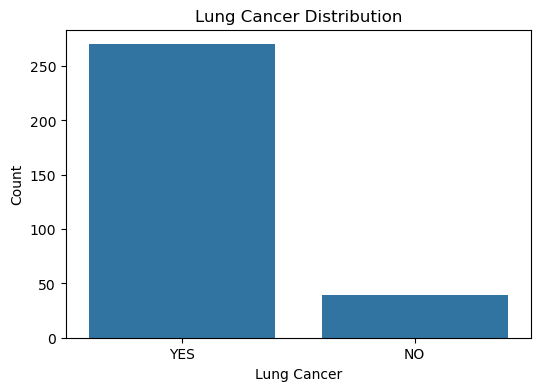

In [41]:
# Target Variable Distribution

print(df["LUNG_CANCER"].value_counts())

# Visualize Target Distribution

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="LUNG_CANCER")

plt.title("Lung Cancer Distribution")
plt.xlabel("Lung Cancer")
plt.ylabel("Count")

plt.show()

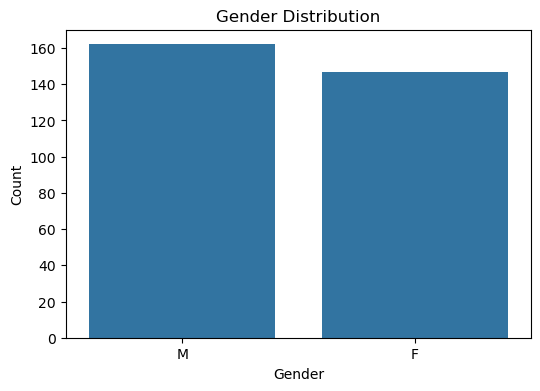

In [42]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="GENDER")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

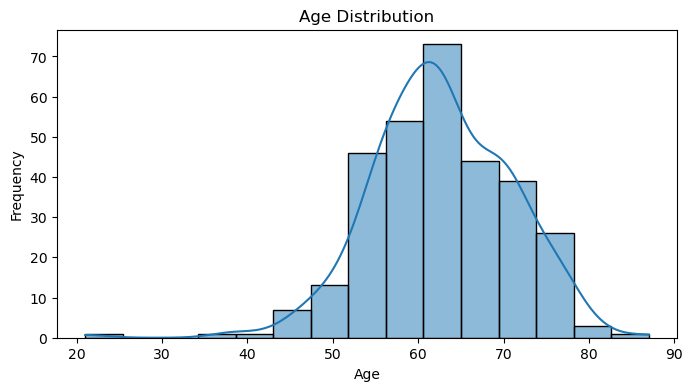

In [43]:
plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x="AGE",
    bins=15,
    kde=True
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

In [44]:
# Check duplicate records

print("Before removing duplicates:", df.shape)

# Remove duplicates

df = df.drop_duplicates()

# Check updated shape

print("After removing duplicates:", df.shape)

Before removing duplicates: (309, 16)
After removing duplicates: (276, 16)


In [45]:
# Check missing values

print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows where target value is missing

df = df.dropna(subset=["LUNG_CANCER"])

# Check missing values again

print("\nMissing values after cleaning:")
print(df.isnull().sum().sum())

Missing values before cleaning:
GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64

Missing values after cleaning:
0


In [46]:
# Remove unnecessary spaces and standardize text

df["GENDER"] = df["GENDER"].astype("string").str.strip().str.upper()

df["LUNG_CANCER"] = (
    df["LUNG_CANCER"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Check categorical values

print("Gender values:", df["GENDER"].unique())

print("Target values:", df["LUNG_CANCER"].unique())

Gender values: <StringArray>
['M', 'F']
Length: 2, dtype: string
Target values: <StringArray>
['YES', 'NO']
Length: 2, dtype: string


In [47]:
# Display cleaned dataset

df.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


In [48]:
# Final dataset information

print("Final Dataset Shape:", df.shape)

print("Total Duplicate Rows:", df.duplicated().sum())

print("Total Missing Values:", df.isnull().sum().sum())

Final Dataset Shape: (276, 16)
Total Duplicate Rows: 0
Total Missing Values: 0


In [49]:
X = df.drop(columns=["LUNG_CANCER"])
y = df["LUNG_CANCER"]
print("Independent Variables (X):", X.shape)

print("Dependent Variable (y):", y.shape)

print("Input Features:", X.columns.tolist())

print(y.value_counts())

Independent Variables (X): (276, 15)
Dependent Variable (y): (276,)
Input Features: ['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH', 'SWALLOWING DIFFICULTY', 'CHEST PAIN']
LUNG_CANCER
YES    238
NO      38
Name: count, dtype: Int64


In [50]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (220, 15)
Testing Data: (56, 15)
Training Target: (220,)
Testing Target: (56,)


In [51]:
print("Training Data Distribution:")
print(y_train.value_counts())

print("\nTesting Data Distribution:")
print(y_test.value_counts())

Training Data Distribution:
LUNG_CANCER
YES    190
NO      30
Name: count, dtype: Int64

Testing Data Distribution:
LUNG_CANCER
YES    48
NO      8
Name: count, dtype: Int64


In [52]:
# Identify categorical columns

categorical_columns = ["GENDER"]

# Identify numerical columns

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
['GENDER']

Numerical Columns:
['AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH', 'SWALLOWING DIFFICULTY', 'CHEST PAIN']


In [53]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Categorical preprocessing

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Numerical preprocessing

numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [54]:
# Combine both transformers

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_transformer, categorical_columns),
        ("num", numerical_transformer, numerical_columns)
    ]
)

print("Feature preprocessing pipeline created successfully!")

Feature preprocessing pipeline created successfully!


In [55]:
# Import Classification Models

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

# Define Models

models = {

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("All six classification models defined successfully!")

All six classification models defined successfully!


In [56]:
# Store trained models

trained_models = {}

# Train each model

for name, classifier in models.items():

    # Create pipeline

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Train model

    model.fit(X_train, y_train)

    # Store trained model

    trained_models[name] = model

    print(name, "trained successfully!")

Decision Tree trained successfully!
Random Forest trained successfully!
Logistic Regression trained successfully!
KNN trained successfully!
SVM trained successfully!
Gradient Boosting trained successfully!


In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
# Store evaluation results

results = []

# Evaluate each trained model

for name, model in trained_models.items():

    # Predict test data

    y_pred = model.predict(X_test)

    # Calculate performance metrics

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        pos_label="YES",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        pos_label="YES",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    # Store results

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(name, "evaluation completed!")

Decision Tree evaluation completed!
Random Forest evaluation completed!
Logistic Regression evaluation completed!
KNN evaluation completed!
SVM evaluation completed!
Gradient Boosting evaluation completed!


In [58]:
# Convert results into DataFrame

comparison = pd.DataFrame(results)

# Sort models by F1 Score

comparison = comparison.sort_values(
    by="F1 Score",
    ascending=False
)

# Display comparison

comparison

,Model,Accuracy,Precision,Recall,F1 Score
4,SVM,0.910714,0.977778,0.916667,0.841539
2,Logistic Regression,0.892857,1.000000,0.875000,0.830303
1,Random Forest,0.910714,0.938776,0.958333,0.807560
3,KNN,0.910714,0.921569,0.979167,0.782440
0,Decision Tree,0.892857,0.937500,0.937500,0.781250
5,Gradient Boosting,0.875000,0.918367,0.937500,0.730584


In [59]:
best_model_name = comparison.iloc[0]["Model"]

print("Best Performing Model:", best_model_name)

print(
    "Best F1 Score:",
    comparison.iloc[0]["F1 Score"]
)

Best Performing Model: SVM
Best F1 Score: 0.8415393322014715


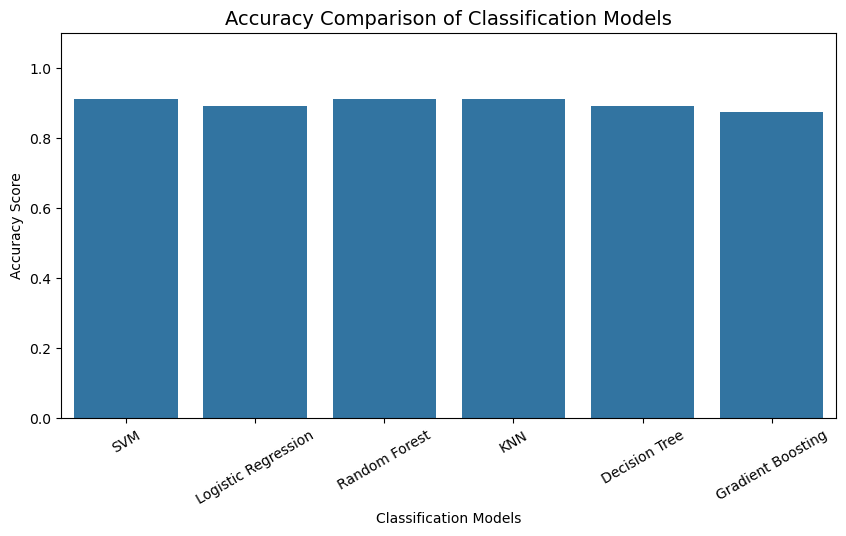

In [60]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Classification Models",
          fontsize=14)

plt.xlabel("Classification Models")
plt.ylabel("Accuracy Score")

plt.xticks(rotation=30)
plt.ylim(0, 1.1)

plt.show()

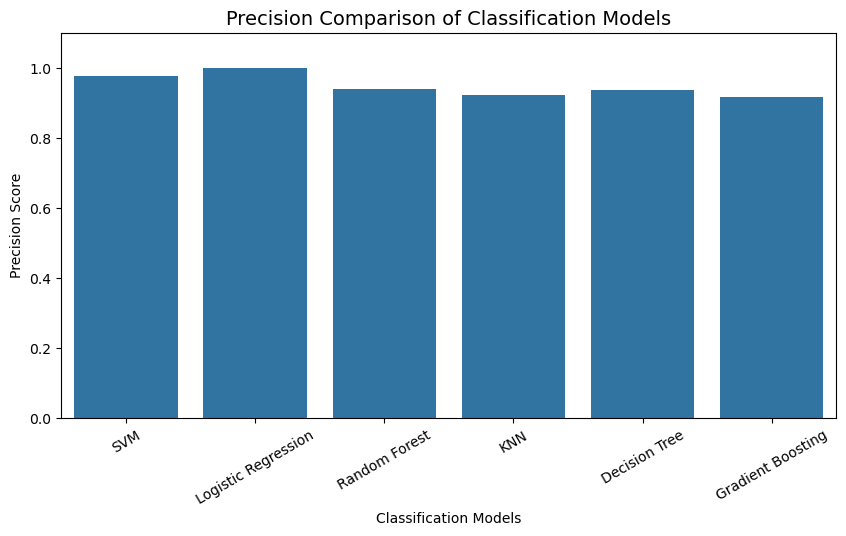

In [61]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Precision"
)

plt.title("Precision Comparison of Classification Models",
          fontsize=14)

plt.xlabel("Classification Models")
plt.ylabel("Precision Score")

plt.xticks(rotation=30)
plt.ylim(0, 1.1)

plt.show()

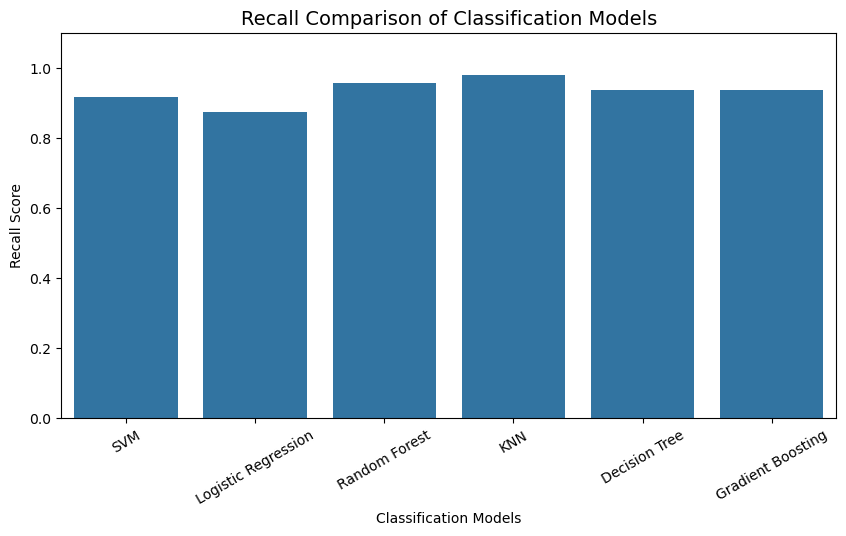

In [62]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Recall"
)

plt.title("Recall Comparison of Classification Models",
          fontsize=14)

plt.xlabel("Classification Models")
plt.ylabel("Recall Score")

plt.xticks(rotation=30)
plt.ylim(0, 1.1)

plt.show()

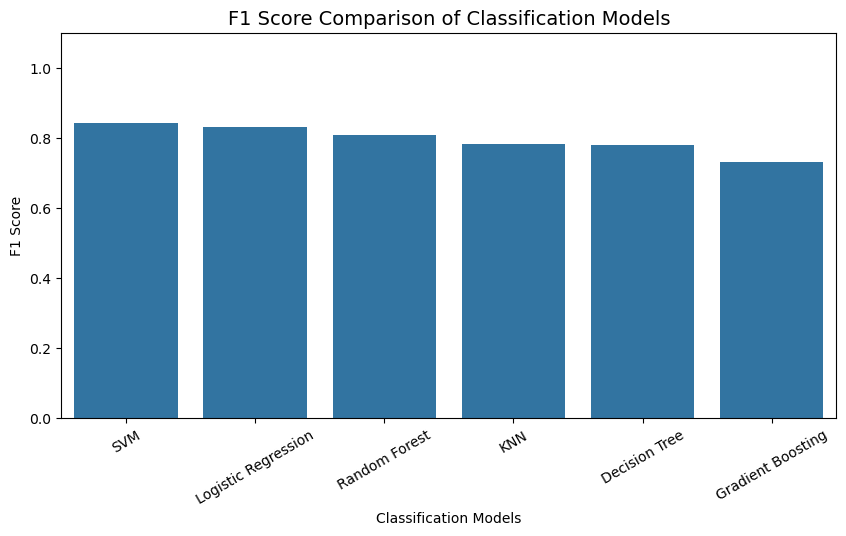

In [63]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="F1 Score"
)

plt.title("F1 Score Comparison of Classification Models",
          fontsize=14)

plt.xlabel("Classification Models")
plt.ylabel("F1 Score")

plt.xticks(rotation=30)
plt.ylim(0, 1.1)

plt.show()

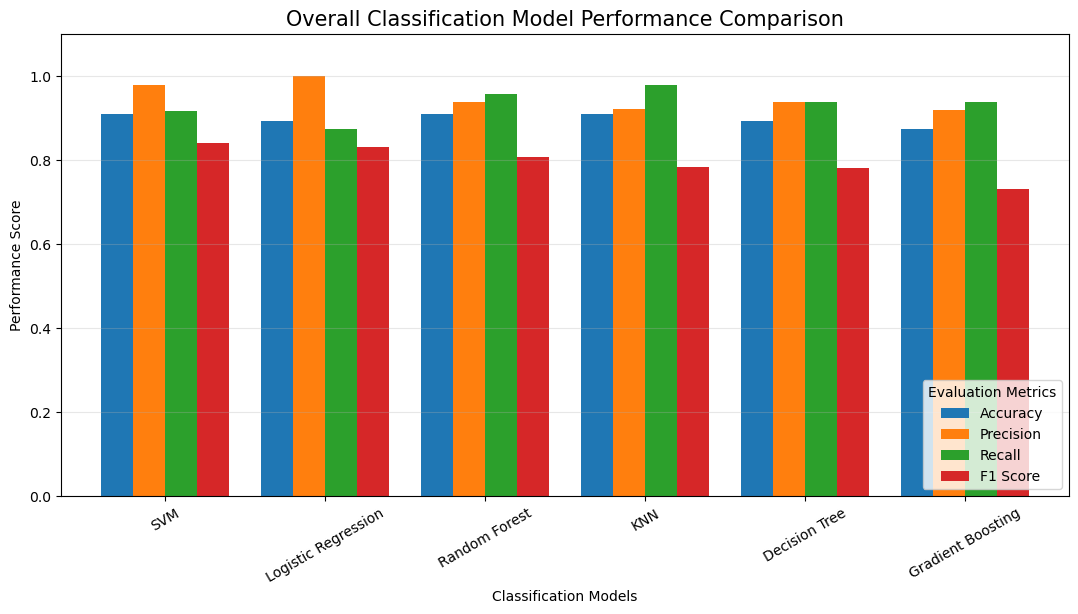

In [64]:
# Overall Model Comparison

comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title(
    "Overall Classification Model Performance Comparison",
    fontsize=15
)

plt.xlabel("Classification Models")
plt.ylabel("Performance Score")

plt.xticks(rotation=30)

plt.ylim(0, 1.1)

plt.legend(
    title="Evaluation Metrics",
    loc="lower right"
)

plt.grid(axis="y", alpha=0.3)

plt.show()

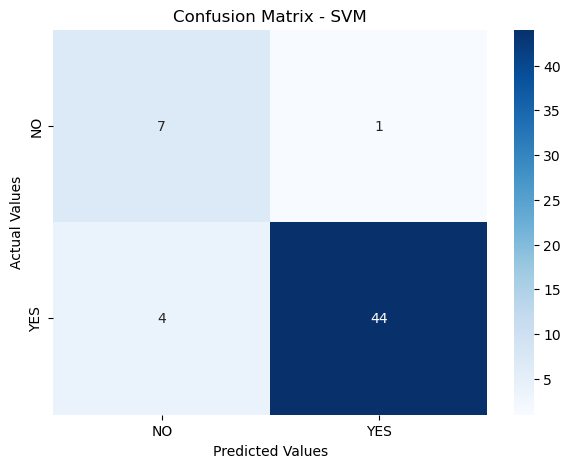

In [65]:
# Select best model

best_model_name = comparison.iloc[0]["Model"]

best_model = trained_models[best_model_name]

# Predict test data

y_pred = best_model.predict(X_test)

# Create confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["NO", "YES"]
)

# Visualize confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NO", "YES"],
    yticklabels=["NO", "YES"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [66]:
# Classification Report

print("Best Model:", best_model_name)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=["NO", "YES"],
        zero_division=0
    )
)

Best Model: SVM

Classification Report:

              precision    recall  f1-score   support

          NO       0.64      0.88      0.74         8
         YES       0.98      0.92      0.95        48

    accuracy                           0.91        56
   macro avg       0.81      0.90      0.84        56
weighted avg       0.93      0.91      0.92        56



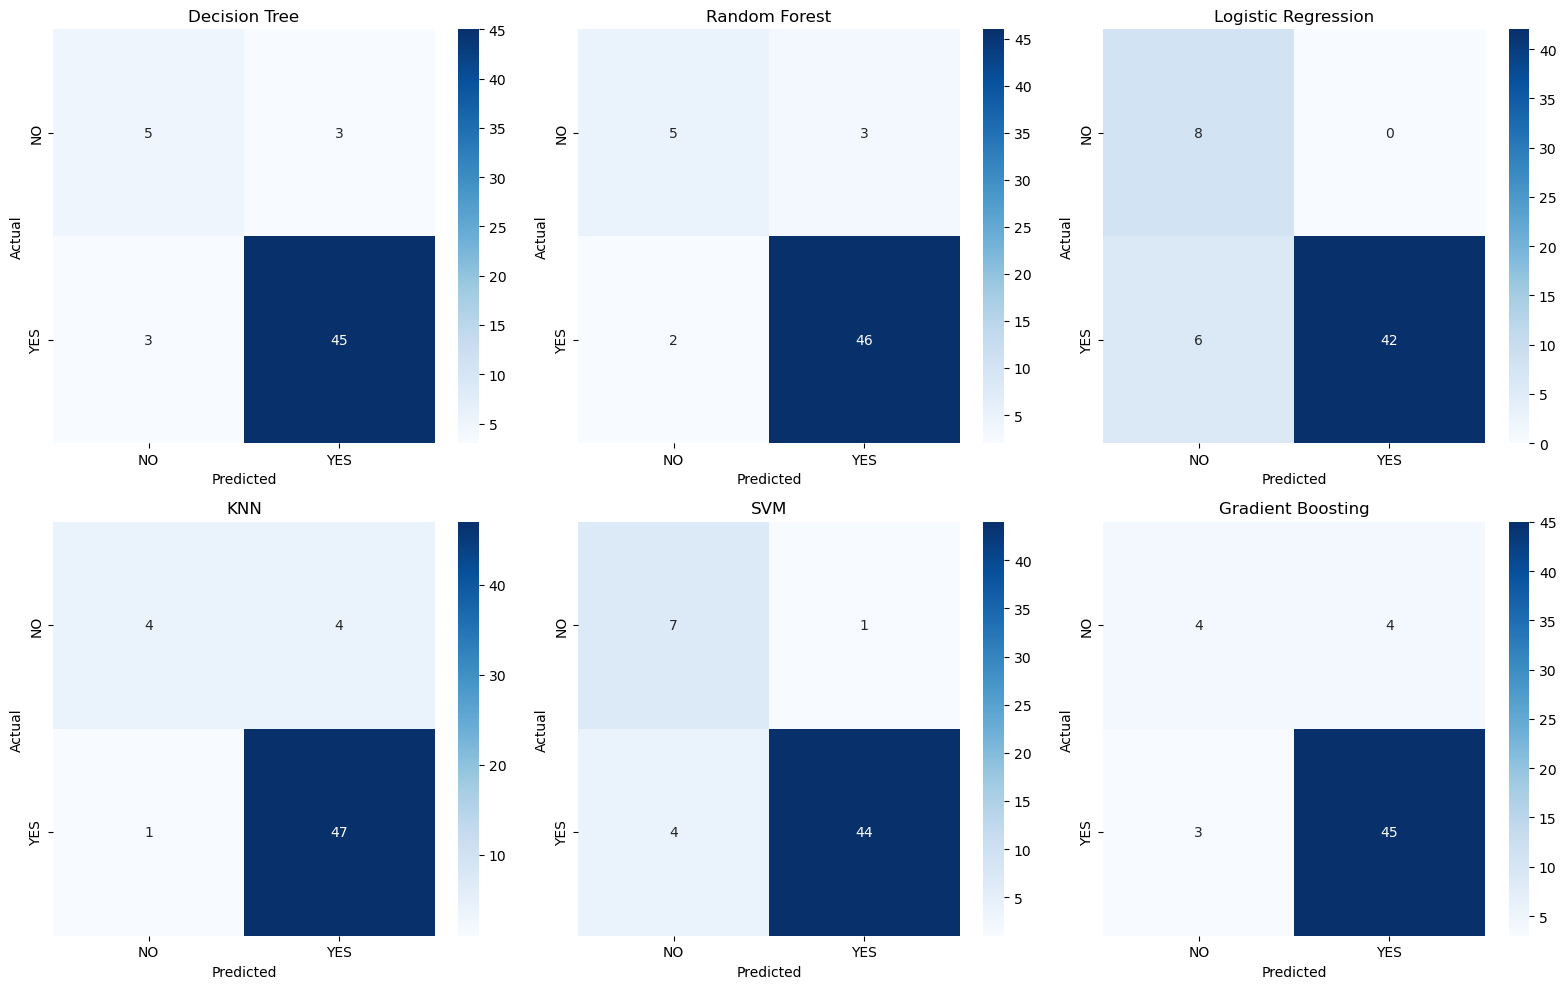

In [67]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

for ax, (name, model) in zip(
    axes.flatten(),
    trained_models.items()
):

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["NO", "YES"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["NO", "YES"],
        yticklabels=["NO", "YES"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [68]:
# Select the best model based on F1 Score
best_model_name = comparison.iloc[0]["Model"]

best_model = trained_models[best_model_name]

# Save the model and its details
model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "features": X.columns.tolist()
}

joblib.dump(model_bundle, "lung_cancer_model.pkl")

# Save the model comparison results
comparison.to_csv("model_comparison.csv", index=False)

print("Model saved successfully!")
print("Best Model:", best_model_name)

Model saved successfully!
Best Model: SVM


In [69]:
loaded_bundle = joblib.load("lung_cancer_model.pkl")

print("Loaded Model:", loaded_bundle["model_name"])
print("Features:", loaded_bundle["features"])

Loaded Model: SVM
Features: ['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH', 'SWALLOWING DIFFICULTY', 'CHEST PAIN']


In [78]:
%%writefile cancer.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

# ==================================================
# 1. PAGE CONFIGURATION
# ==================================================

st.set_page_config(
    page_title="LungSense AI",
    page_icon="🫁",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ==================================================
# 2. LOAD SAVED MODEL
# ==================================================

BASE_DIR = Path(__file__).resolve().parent

MODEL_PATH = BASE_DIR / "lung_cancer_model.pkl"
COMPARISON_PATH = BASE_DIR / "model_comparison.csv"

if not MODEL_PATH.exists():
    st.error(
        "Model file not found! "
        "Please place lung_cancer_model.pkl "
        "in the same folder as cancer.py."
    )
    st.stop()

bundle = joblib.load(MODEL_PATH)

model = bundle["model"]
model_name = bundle["model_name"]
features = bundle["features"]

if COMPARISON_PATH.exists():
    comparison = pd.read_csv(COMPARISON_PATH)
else:
    comparison = pd.DataFrame()


# ==================================================
# 3. CUSTOM DARK MODE CSS
# ==================================================

st.markdown("""
<style>

/* Main Background */

.stApp {
    background-color: #0b1220 !important;
    color: #ffffff !important;
}

/* Main Content */

[data-testid="stMain"] {
    background-color: #0b1220 !important;
}

/* Sidebar */

[data-testid="stSidebar"] {
    background-color: #111c2e !important;
}

[data-testid="stSidebar"] * {
    color: #ffffff !important;
}

/* All Labels */

.stApp label {
    color: #ffffff !important;
    font-weight: 600 !important;
}

/* General Text */

.stApp p {
    color: #e2e8f0;
}

/* Headings */

.stApp h1,
.stApp h2,
.stApp h3,
.stApp h4 {
    color: #ffffff !important;
}

/* Selectbox Background */

.stSelectbox div[data-baseweb="select"] > div {
    background-color: #1e293b !important;
    border: 1px solid #475569 !important;
    border-radius: 8px !important;
}

/* Selectbox Text */

.stSelectbox div[data-baseweb="select"] span {
    color: #ffffff !important;
}

/* Selectbox Arrow */

.stSelectbox div[data-baseweb="select"] svg {
    fill: #ffffff !important;
}

/* Dropdown Options Menu */

div[data-baseweb="popover"] {
    background-color: #1e293b !important;
}

div[role="listbox"] {
    background-color: #1e293b !important;
}

div[role="option"] {
    background-color: #1e293b !important;
    color: #ffffff !important;
}

/* Dropdown Hover */

div[role="option"]:hover {
    background-color: #334155 !important;
    color: #38d9c5 !important;
}

/* Slider */

.stSlider label {
    color: #ffffff !important;
}

/* Slider Value */

.stSlider [data-testid="stThumbValue"] {
    color: #38d9c5 !important;
}

/* Form */

[data-testid="stForm"] {
    background-color: #111c2e !important;
    border: 1px solid #334155 !important;
    border-radius: 12px !important;
    padding: 20px !important;
}

/* Form Submit Button */

.stFormSubmitButton button {
    background: linear-gradient(
        90deg,
        #0891b2,
        #20bfae
    ) !important;

    color: #ffffff !important;
    border: none !important;
    border-radius: 10px !important;
    font-weight: bold !important;
    font-size: 17px !important;
    padding: 12px !important;
    width: 100% !important;
}

/* Button Hover */

.stButton button:hover,
.stFormSubmitButton button:hover {
    background-color: #38d9c5 !important;
    color: #071522 !important;
    border: none !important;
}

/* Regular Buttons */

.stButton button {
    background-color: #20bfae !important;
    color: #071522 !important;
    border-radius: 8px !important;
    font-weight: bold !important;
}

/* Main Title */

.main-title {
    font-size: 42px;
    font-weight: 800;
    color: #38d9c5 !important;
}

/* Subtitle */

.subtitle {
    color: #cbd5e1 !important;
    font-size: 17px;
}

/* Metric Cards */

.metric-card {
    background: linear-gradient(
        135deg,
        #17283d,
        #123b46
    );

    padding: 22px;
    border-radius: 15px;
    border: 1px solid #28566a;
    text-align: center;
}

/* Metric Values */

.metric-value {
    font-size: 30px;
    font-weight: bold;
    color: #38d9c5 !important;
}

/* Metric Labels */

.metric-label {
    color: #ffffff !important;
    font-size: 14px;
}

/* Section Title */

.section-title {
    color: #38d9c5 !important;
    font-size: 25px;
    font-weight: bold;
}

/* Dataframe */

[data-testid="stDataFrame"] {
    background-color: #111c2e !important;
}

/* Success Message */

[data-testid="stAlert"] {
    color: #ffffff !important;
}

/* Metric Text */

[data-testid="stMetricValue"] {
    color: #38d9c5 !important;
}

[data-testid="stMetricLabel"] {
    color: #ffffff !important;
}

/* Captions */

.stCaption {
    color: #cbd5e1 !important;
}

/* Footer */

.footer {
    color: #94a3b8 !important;
    text-align: center;
    font-size: 14px;
    padding: 15px;
}

/* Divider */

hr {
    border-color: #334155 !important;
}

</style>
""", unsafe_allow_html=True)


# ==================================================
# 4. SIDEBAR NAVIGATION
# ==================================================

st.sidebar.markdown(
    """
    <h1 style="color:#38d9c5;">
        🫁 LungSense AI
    </h1>
    """,
    unsafe_allow_html=True
)

st.sidebar.caption(
    "Smart Respiratory Health Insights"
)

page = st.sidebar.radio(
    "NAVIGATION",
    [
        "Overview",
        "Health Assessment",
        "Model Performance",
        "About Project"
    ]
)

st.sidebar.markdown("---")

st.sidebar.info(
    "Educational machine-learning project. "
    "Not a medical diagnostic system."
)


# ==================================================
# 5. OVERVIEW PAGE
# ==================================================

if page == "Overview":

    st.markdown(
        '<div class="main-title">'
        'Welcome to LungSense AI'
        '</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="subtitle">'
        'Explore survey patterns and machine-learning predictions.'
        '</div>',
        unsafe_allow_html=True
    )

    st.write("")

    col1, col2, col3 = st.columns(3)

    with col1:
        st.markdown("""
        <div class="metric-card">
            <div class="metric-value">309</div>
            <div class="metric-label">Original Dataset Records</div>
        </div>
        """, unsafe_allow_html=True)

    with col2:
        st.markdown("""
        <div class="metric-card">
            <div class="metric-value">15</div>
            <div class="metric-label">Input Features</div>
        </div>
        """, unsafe_allow_html=True)

    with col3:
        st.markdown(f"""
        <div class="metric-card">
            <div class="metric-value">6</div>
            <div class="metric-label">ML Algorithms Evaluated</div>
        </div>
        """, unsafe_allow_html=True)
    st.write("")

    st.markdown(
        '<div class="section-title">'
        'Explore the Application'
        '</div>',
        unsafe_allow_html=True
    )

    left, right = st.columns(2)

    with left:

        st.info(
            "**Health Assessment**\n\n"
            "Enter survey information and explore "
            "the machine-learning prediction."
        )

    with right:

        st.info(
            "**Model Performance**\n\n"
            "Compare the performance of six "
            "classification algorithms."
        )

    st.warning(
        "This application is for educational purposes only. "
        "Its predictions do not establish whether someone "
        "has lung cancer."
    )


# ==================================================
# 6. HEALTH ASSESSMENT PAGE
# ==================================================

elif page == "Health Assessment":

    st.markdown(
        '<div class="main-title">'
        'Health Assessment'
        '</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="subtitle">'
        'Enter survey responses to explore a '
        'machine-learning prediction.'
        '</div>',
        unsafe_allow_html=True
    )

    st.write("")

    with st.form("health_form"):

        st.markdown(
            '<div class="section-title">'
            'Personal Information'
            '</div>',
            unsafe_allow_html=True
        )

        col1, col2 = st.columns(2)

        with col1:

            gender = st.selectbox(
                "Gender",
                ["M", "F"]
            )

        with col2:

            age = st.slider(
                "Age",
                min_value=21,
                max_value=87,
                value=40
            )

        st.markdown("---")

        st.markdown(
            '<div class="section-title">'
            'Survey Responses'
            '</div>',
            unsafe_allow_html=True
        )

        st.caption(
            "Select the original dataset response code "
            "for each survey feature."
        )

        survey_features = [

            "SMOKING",

            "YELLOW_FINGERS",

            "ANXIETY",

            "PEER_PRESSURE",

            "CHRONIC DISEASE",

            "FATIGUE",

            "ALLERGY",

            "WHEEZING",

            "ALCOHOL CONSUMING",

            "COUGHING",

            "SHORTNESS OF BREATH",

            "SWALLOWING DIFFICULTY",

            "CHEST PAIN"

        ]

        responses = {}

        col1, col2 = st.columns(2)

        for index, feature in enumerate(survey_features):

            with (col1 if index % 2 == 0 else col2):

                responses[feature] = st.selectbox(

                    feature.replace("_", " ").title(),

                    options=[1, 2],

                    format_func=lambda x: f"Code {x}",

                    key=f"input_{feature}"

                )

        st.markdown("---")

        submitted = st.form_submit_button(
            "🫁 Generate Prediction",
            use_container_width=True
        )

    # ----------------------------------------------
    # PREDICTION
    # ----------------------------------------------

    if submitted:

        user_input = {

            "GENDER": gender,

            "AGE": age,

            **responses

        }

        # Match input column names with saved model.
        # This also handles trailing spaces in old model features.

        normalized_input = {
            str(key).strip(): value
            for key, value in user_input.items()
        }

        missing_features = [
            feature for feature in features
            if str(feature).strip() not in normalized_input
        ]

        if missing_features:

            st.error(
                "Missing input features: "
                + ", ".join(missing_features)
            )

        else:

            input_df = pd.DataFrame([
                {
                    feature: normalized_input[str(feature).strip()]
                    for feature in features
                }
            ])

            try:

                prediction = model.predict(input_df)[0]

                st.markdown("---")

                st.markdown(
                    '<div class="section-title">'
                    'Prediction Result'
                    '</div>',
                    unsafe_allow_html=True
                )

                if prediction == "YES":

                    st.error(
                        "⚠️ The model predicts: YES"
                    )

                else:

                    st.success(
                        "The model predicts: NO"
                    )

                st.caption(
                    "This is a machine-learning classification "
                    "output, not a medical diagnosis."
                )

                # Prediction probability

                if hasattr(model, "predict_proba"):

                    probabilities = model.predict_proba(
                        input_df
                    )[0]

                    classes = model.classes_

                    confidence = probabilities[
                        list(classes).index(prediction)
                    ] * 100

                    st.metric(
                        "Model Prediction Confidence",
                        f"{confidence:.2f}%"
                    )

                    st.caption(
                        "This percentage represents the model's "
                        "output confidence, not a person's "
                        "actual probability of having cancer."
                    )

            except Exception as e:

                st.error(
                    f"Prediction Error: {e}"
                )


# ==================================================
# 7. MODEL PERFORMANCE PAGE
# ==================================================

elif page == "Model Performance":

    st.markdown(
        '<div class="main-title">'
        'Model Performance'
        '</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="subtitle">'
        'Compare the six trained classification models.'
        '</div>',
        unsafe_allow_html=True
    )

    if not comparison.empty:

        st.markdown(
            '<div class="section-title">'
            'Model Comparison Table'
            '</div>',
            unsafe_allow_html=True
        )

        st.dataframe(

            comparison.style.format({

                "Accuracy": "{:.3f}",

                "Precision": "{:.3f}",

                "Recall": "{:.3f}",

                "F1 Score": "{:.3f}"

            }),

            use_container_width=True

        )

        st.write("")

        metric = st.selectbox(

            "Choose Evaluation Metric",

            [
                "Accuracy",
                "Precision",
                "Recall",
                "F1 Score"
            ]

        )

        fig, ax = plt.subplots(figsize=(10, 5))

        fig.patch.set_facecolor("#0b1220")

        ax.set_facecolor("#111c2e")

        sorted_data = comparison.sort_values(
            by=metric,
            ascending=False
        )

        ax.bar(

            sorted_data["Model"],

            sorted_data[metric],

            color="#20bfae"

        )

        ax.set_title(
            f"Model Comparison - {metric}",
            color="white",
            fontsize=15
        )

        ax.set_ylabel(
            metric,
            color="white"
        )

        ax.set_xlabel(
            "Machine Learning Models",
            color="white"
        )

        ax.tick_params(
            axis="x",
            rotation=35,
            colors="white"
        )

        ax.tick_params(
            axis="y",
            colors="white"
        )

        ax.set_ylim(0, 1.1)

        ax.spines["bottom"].set_color("#475569")
        ax.spines["left"].set_color("#475569")

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.grid(
            axis="y",
            alpha=0.2
        )

        plt.tight_layout()

        st.pyplot(fig)

        plt.close(fig)

        st.success(
            f"Saved Best Model: {model_name}"
        )

    else:

        st.warning(
            "Model comparison file was not found."
        )


# ==================================================
# 8. ABOUT PROJECT PAGE
# ==================================================

elif page == "About Project":

    st.markdown(
        '<div class="main-title">'
        'About LungSense AI'
        '</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="subtitle">'
        'Machine Learning Based Lung Cancer Classification Project'
        '</div>',
        unsafe_allow_html=True
    )

    st.write("")

    st.markdown("""
    ### Project Overview

    LungSense AI is an educational machine-learning project
    developed using Python and Streamlit.

    It explores survey-based lung cancer classification data
    and demonstrates how different machine-learning algorithms
    can be trained and compared.

    ---

    ### Machine Learning Algorithms

    - Decision Tree Classifier
    - Random Forest Classifier
    - Logistic Regression
    - K-Nearest Neighbors
    - Support Vector Machine
    - Gradient Boosting Classifier

    ---

    ### Technologies Used

    - Python
    - Pandas
    - NumPy
    - Scikit-learn
    - Matplotlib
    - Streamlit
    - Joblib

    ---

    ### Project Objective

    To demonstrate data preprocessing, model training,
    classification evaluation, and interactive presentation
    of machine-learning outputs.
    """)

    st.warning(
        "Medical Disclaimer: This project is not clinically "
        "validated. It cannot diagnose, screen for, or rule out "
        "lung cancer. Do not use its predictions to make "
        "healthcare decisions. Consult a qualified healthcare "
        "professional for medical concerns."
    )


# ==================================================
# 9. FOOTER
# ==================================================

st.markdown("---")

st.markdown(
    """
    <div class="footer">
        LungSense AI |
        Machine Learning Project |
        Educational Use Only
    </div>
    """,
    unsafe_allow_html=True
)


Writing cancer.py
